In [2]:
import json, gzip, pathlib
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

BASE = pathlib.Path('T6')

def load(file, name):
    """Return one metric from a VictoriaMetrics export as a time-indexed Series."""
    with gzip.open(BASE / file, 'rt') as f:
        for line in f:
            d = json.loads(line)
            if d['metric'].get('__name__') == name:
                return pd.Series(d['values'], index=pd.to_datetime(d['timestamps'], unit='ms', utc=True)).sort_index()

in_kbps  = load('export_pi5_127.0.0.1.jsonl.gz', 'snmp_in_bps')  / 1e3
out_kbps = load('export_pi5_127.0.0.1.jsonl.gz', 'snmp_out_bps') / 1e3
state    = load('export_pi5_127.0.0.1.jsonl.gz', 'monitor_backhaul_state')       # 1 = down
buffer   = load('export_vmagent_pi.jsonl.gz', 'vmagent_remotewrite_pending_data_bytes') / 1e3

# event times (UTC) from the monitor's journal, the test log and the laptop's iperf3 server log
T = lambda s: pd.Timestamp(f'2026-10-23T{s}Z')
outages   = [('Outage 1', T('19:45:26'), T('19:55:24')),      # journal: backhaul down -> up
             ('Outage 2', T('20:20:35'), T('21:05:34'))]
sleep     = (T('20:01:04'), T('20:03:33'))                    # test log: receiver unreachable, internet up
netmon_ip = (T('19:35:58'), T('19:36:34'))                    # laptop log: monitor's own iperf3 set
print(f'{len(in_kbps)} SNMP samples, {len(buffer)} buffer samples')

717 SNMP samples, 480 buffer samples


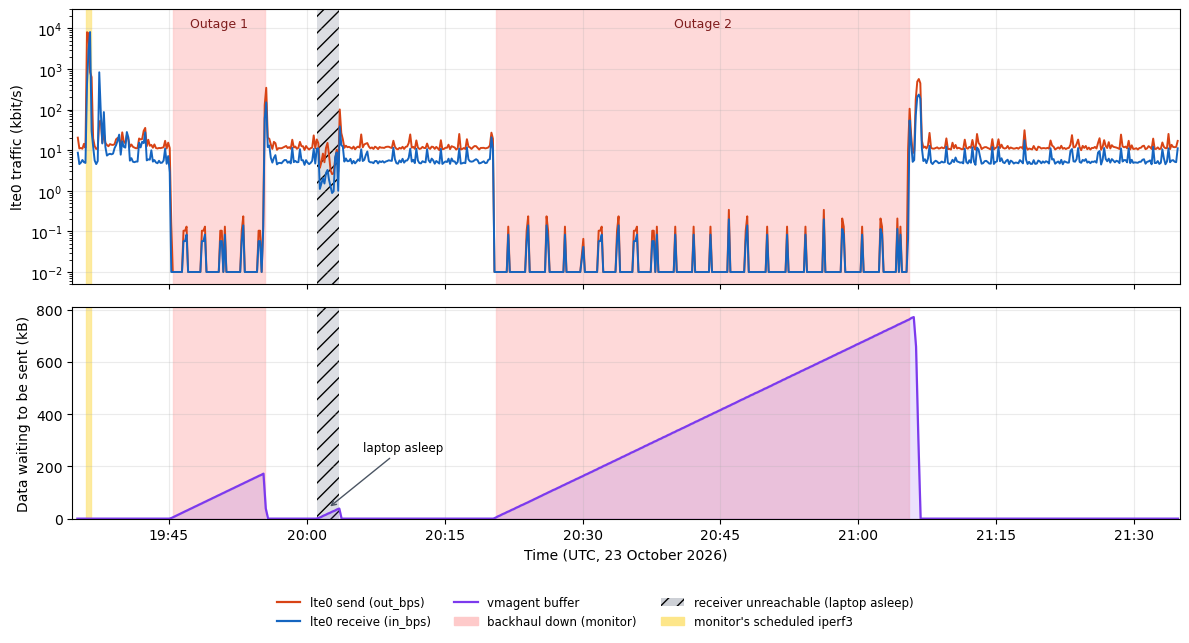

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True,
                               gridspec_kw={'height_ratios': [1.3, 1]})

def shade(ax, label=True):
    for name, t0, t1 in outages:
        ax.axvspan(t0, t1, color='#fecaca', alpha=0.7, zorder=0)
        if label:
            ax.text(t0 + (t1 - t0) / 2, 0.97, name, transform=ax.get_xaxis_transform(),
                    ha='center', va='top', fontsize=9, color='#7f1d1d')
    ax.axvspan(*sleep, facecolor='#9ca3af', alpha=0.35, hatch='//', zorder=0)
    ax.axvspan(*netmon_ip, color='#fde68a', alpha=0.8, zorder=0)

# top: traffic the router counted on lte0 (log scale, so idle and outage levels are visible)
ax1.plot(out_kbps.index, out_kbps.clip(lower=0.01), color='#d84315', lw=1.4, label='send (out_bps)')
ax1.plot(in_kbps.index,  in_kbps.clip(lower=0.01),  color='#1565c0', lw=1.4, label='receive (in_bps)')
ax1.set_yscale('log'); ax1.set_ylim(0.005, 3e4)
ax1.set_ylabel('lte0 traffic (kbit/s)')
shade(ax1)

# bottom: data waiting in the vmagent buffer
ax2.plot(buffer.index, buffer, color='#7c3aed', lw=1.6)
ax2.fill_between(buffer.index, buffer, color='#7c3aed', alpha=0.15)
ax2.set_ylabel('Data waiting to be sent (kB)')
ax2.set_ylim(bottom=0)
shade(ax2, label=False)
ax2.annotate('laptop asleep', xy=(sleep[0] + (sleep[1] - sleep[0]) / 2, 40), xytext=(T('20:10:30'), 260),
             fontsize=8.5, ha='center', arrowprops=dict(arrowstyle='->', color='#4b5563'))

ax2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz='UTC'))
ax2.set_xlabel('Time (UTC, 23 October 2026)')
for ax in (ax1, ax2):
    ax.grid(True, alpha=0.25); ax.set_xlim(T('19:34:30'), T('21:35:00'))

handles = [Line2D([0], [0], color='#d84315', lw=1.6, label='lte0 send (out_bps)'),
           Line2D([0], [0], color='#1565c0', lw=1.6, label='lte0 receive (in_bps)'),
           Line2D([0], [0], color='#7c3aed', lw=1.6, label='vmagent buffer'),
           mpatches.Patch(color='#fecaca', label='backhaul down (monitor)'),
           mpatches.Patch(facecolor='#9ca3af', alpha=0.5, hatch='//', label='receiver unreachable (laptop asleep)'),
           mpatches.Patch(color='#fde68a', label="monitor's scheduled iperf3")]
fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig('t5_backhaul_outage.png', dpi=180, bbox_inches='tight')
plt.savefig('t5_backhaul_outage.pdf', bbox_inches='tight')
plt.show()